# AI-Based Smart Traffic Violation Detection System

Detects **red-light violations** and **riders without helmets** from traffic video using YOLO object detection and ByteTrack tracking, and saves every violation with image evidence and a CSV log.

**How to use this notebook**
1. Put your videos in `input_videos/` and (optional) your trained helmet weights in `weights/` (see section 5).
2. Edit the **Settings** cell (section 1) if you want to change the video, stop line or signal mode.
3. Run **Kernel → Restart and Run All**. Every section checks what it needs and **skips with a clear message** instead of failing if something is missing.

**Objectives covered:** detect vehicles, riders, helmets and signal state (YOLO) → apply rule logic (stop line + red signal, helmet check) → capture evidence image, time and violation type → store the records in CSV → reduce manual monitoring.

**Important honesty notes**
- The red-light logic needs a *signal state*. If your video has no visible traffic light, `SIGNAL_MODE = 'simulate'` uses a made-up red/green schedule to demonstrate the pipeline; those records are labelled `simulated` in the log and are **not** real violations.
- The helmet model only works well on camera angles similar to its training data. Check the rider contact sheet before trusting results.

**Submission status:** trained helmet weights are included under `weights/helmet_local/weights/best.pt`. The default run processes the complete selected video. Training is disabled by default; enable it only for retraining.


## 1. Settings

Everything you may want to change is in this one cell. Stop line and signal box are given as **fractions** of the frame (0 to 1), so they work at any video size. Section 4 draws a grid on a frame to help you choose them.

In [1]:
# ===================== SETTINGS (edit here) =====================

# --- video selection -------------------------------------------------
VIDEO_NAME = 'download.mp4'            # e.g. 'junction.mp4'. None = pick automatically from input_videos/
HELMET_VIDEO_NAME = 'download.mp4'     # video for the helmet check. None = same as VIDEO_NAME
PREFERRED_VIDEOS = ['junction.mp4', 'download.mp4', 'lolm.mp4']   # used when VIDEO_NAME is None
FRAME_MAX_WIDTH = 1280       # frames wider than this are shrunk (keeps 4K videos fast)
FRAME_STRIDE = 1             # 1 = every frame, 2 = every second frame (faster)
MAX_FRAMES = None            # e.g. 200 for a quick test run. None = whole video
CALIB_FRAME = 30             # frame used for the preview and grid in section 4

# --- vehicle detection / tracking -------------------------------------
VEHICLE_MODEL = 'yolov8s.pt'         # downloads automatically the first time (needs internet)
VEHICLE_CLASSES = [2, 3, 5, 7]       # COCO: car, motorcycle, bus, truck
VEH_CONF = 0.35
IMGSZ = None                         # None = 1280 on GPU, 960 on CPU
MIN_TRACK_AGE = 5                    # ignore track IDs seen for fewer frames than this

# --- stop line and red-light rule --------------------------------------
STOP_LINE = ((0.0, 0.65), (1.0, 0.65))   # ((x1, y1), (x2, y2)) as fractions of width/height
TRAFFIC_DIRECTION = 'any'                # 'any', 'up' or 'down' (direction of vehicles that must stop)
SIGNAL_MODE = 'simulate'                 # 'simulate' | 'detect' | 'off'
SIGNAL_SCHEDULE = [(0.0, 'green'), (3.0, 'red'), (9.0, 'green')]   # used when 'simulate': (start second, state)
SIGNAL_ROI = None                        # (x1, y1, x2, y2) fractions around the traffic light, for 'detect'
SIGNAL_SMOOTH_FRAMES = 7                 # majority vote over this many frames
RED_GRACE_S = 0.5                        # signal must have been red this long before a crossing counts

# --- helmet check ---------------------------------------------------------
HELMET_CONF = 0.25
MIN_NOHELMET_VOTES = 3       # frames that must say 'no helmet' before a rider is flagged
MIN_CROP_SIZE = 20           # skip rider crops smaller than this (pixels)
TARGET_CROP_H = 224          # small rider crops are enlarged to this height before the helmet model

# --- optional helmet training (needs datasets/helmet_dataset.zip; slow on CPU) -
TRAIN_HELMET = False
HELMET_EPOCHS = 30
EVALUATE_HELMET = True       # print precision / recall / mAP if weights and dataset are available

# =================================================================


## 2. Environment, folders and helper functions

This cell checks which packages are installed, finds the project folder, and defines helpers used later. It never installs anything by itself. If something is missing, it prints the exact `pip` command.

In [2]:
import sys, shutil, subprocess, zipfile, csv, time, math
from pathlib import Path
from collections import Counter, deque
from datetime import datetime
from base64 import b64encode
import numpy as np

try:
    from IPython.display import display, Image, HTML
except ImportError:                      # plain Python fallback
    def display(*a, **k): pass
    Image = HTML = lambda *a, **k: None

try:
    import cv2
    HAVE_CV2 = True
except ImportError:
    HAVE_CV2 = False

try:
    import pandas as pd
    HAVE_PD = True
except ImportError:
    HAVE_PD = False

try:
    import yaml
    HAVE_YAML = True
except ImportError:
    HAVE_YAML = False

try:
    import torch
    CUDA = bool(torch.cuda.is_available())
except Exception:
    CUDA = False

try:
    from ultralytics import YOLO
    HAVE_YOLO = True
    YOLO_ERROR = ''
except Exception as e:                   # missing package or a broken torch install
    HAVE_YOLO = False
    YOLO_ERROR = f'{type(e).__name__}: {e}'

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except Exception as e:
        print('Could not mount Google Drive:', e)

def find_project_root():
    if IN_COLAB:
        return Path('/content/drive/MyDrive/SmartTrafficViolation')
    here = Path.cwd()
    for cand in (here, here.parent, Path(r'D:\afaf')):
        try:
            if (cand / 'input_videos').exists():
                return cand
        except OSError:
            pass
    return here

PROJECT_ROOT = find_project_root()
VIDEO_DIR = PROJECT_ROOT / 'input_videos'
WEIGHTS_DIR = PROJECT_ROOT / 'weights'
DATASET_DIR = PROJECT_ROOT / 'datasets'
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
WORK_DIR = PROJECT_ROOT / 'work'
for _d in (VIDEO_DIR, WEIGHTS_DIR, DATASET_DIR, OUTPUT_DIR, WORK_DIR):
    _d.mkdir(parents=True, exist_ok=True)

if IMGSZ is None:
    IMGSZ = 1280 if CUDA else 960

RESULTS = {}      # filled by the pipelines, summarised in section 9

print('Python        :', sys.version.split()[0])
print('Project folder:', PROJECT_ROOT.resolve())
print('GPU (CUDA)    :', CUDA, '' if CUDA else '(running on CPU: fine for these short clips, slow for training)')
print('OpenCV        :', HAVE_CV2)
print('Ultralytics   :', HAVE_YOLO, YOLO_ERROR)
print('pandas / yaml :', HAVE_PD, '/', HAVE_YAML)
print('ffmpeg        :', shutil.which('ffmpeg') or 'not found (optional, only used to make browser-playable videos)')

_missing = []
if not HAVE_CV2: _missing.append('opencv-python')
if not HAVE_YOLO: _missing.append('ultralytics lap')
if not HAVE_PD: _missing.append('pandas')
if not HAVE_YAML: _missing.append('pyyaml')
if _missing:
    print('\nSome packages are missing. In a terminal (with your environment active) run:')
    print('    pip install ' + ' '.join(_missing))
    print('then restart the kernel. Sections that need them will be skipped until then.')

READY_VIDEO = HAVE_CV2
READY_DETECT = HAVE_CV2 and HAVE_YOLO

# ------------------------------------------------------------------ helpers
def show(img, width=800):
    # Display a BGR image in the notebook.
    if not HAVE_CV2 or img is None:
        print('(nothing to show)')
        return
    h, w = img.shape[:2]
    if w > width:
        img = cv2.resize(img, (width, max(1, int(h * width / w))))
    ok, buf = cv2.imencode('.png', img)
    if ok:
        display(Image(data=buf.tobytes()))

def list_videos():
    exts = {'.mp4', '.avi', '.mov', '.mkv', '.webm'}
    try:
        return sorted(p for p in VIDEO_DIR.glob('*') if p.is_file() and p.suffix.lower() in exts)
    except OSError:
        return []

def pick_video(name=None):
    vids = list_videos()
    if not vids:
        return None
    if name:
        for v in vids:
            if v.name.lower() == name.lower():
                return v
        print(f"Video '{name}' not found in {VIDEO_DIR}. Available: {[v.name for v in vids]}")
        return None
    for pref in PREFERRED_VIDEOS:
        for v in vids:
            if v.name.lower() == pref.lower():
                return v
    return vids[0]

def video_info(path):
    # Basic facts about a video, plus the processing size after shrinking. None if it cannot be opened.
    if not HAVE_CV2 or path is None:
        return None
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        cap.release()
        return None
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    if w <= 0 or h <= 0:
        return None
    if not fps or fps != fps or fps <= 0:
        fps = 30.0
    scale = min(1.0, FRAME_MAX_WIDTH / w)
    out_w = max(2, int(round(w * scale / 2)) * 2)
    out_h = max(2, int(round(h * scale / 2)) * 2)
    return {'path': Path(path), 'width': w, 'height': h, 'fps': float(fps), 'frames': frames,
            'out_w': out_w, 'out_h': out_h}

def iter_frames(info):
    # Yield (original_frame_index, frame) at processing size, honouring FRAME_STRIDE and MAX_FRAMES.
    cap = cv2.VideoCapture(str(info['path']))
    idx, used = 0, 0
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            if idx % max(1, FRAME_STRIDE) == 0:
                if frame.shape[1] != info['out_w'] or frame.shape[0] != info['out_h']:
                    frame = cv2.resize(frame, (info['out_w'], info['out_h']))
                yield idx, frame
                used += 1
                if MAX_FRAMES is not None and used >= MAX_FRAMES:
                    break
            idx += 1
    finally:
        cap.release()

def read_frame(info, index):
    cap = cv2.VideoCapture(str(info['path']))
    cap.set(cv2.CAP_PROP_POS_FRAMES, max(0, index))
    ok, frame = cap.read()
    cap.release()
    if not ok:
        return None
    if frame.shape[1] != info['out_w'] or frame.shape[0] != info['out_h']:
        frame = cv2.resize(frame, (info['out_w'], info['out_h']))
    return frame

def load_model(spec):
    if not HAVE_YOLO:
        print('Ultralytics is not available, skipping.', YOLO_ERROR)
        return None
    try:
        local = WEIGHTS_DIR / str(spec)
        return YOLO(str(local if local.exists() else spec))
    except Exception as e:
        print(f'Could not load model {spec}: {type(e).__name__}: {e}')
        print('If this is the first run, the model is downloaded from the internet. Check your connection.')
        return None

def rel_to_px(pt, w, h):
    return (int(round(pt[0] * w)), int(round(pt[1] * h)))

def side_of_line(pt, p1, p2):
    return (p2[0] - p1[0]) * (pt[1] - p1[1]) - (p2[1] - p1[1]) * (pt[0] - p1[0])

def within_segment(pt, p1, p2, tol=0.02):
    dx, dy = p2[0] - p1[0], p2[1] - p1[1]
    denom = dx * dx + dy * dy
    if denom == 0:
        return False
    t = ((pt[0] - p1[0]) * dx + (pt[1] - p1[1]) * dy) / denom
    return -tol <= t <= 1 + tol

def scheduled_state(t, schedule):
    state = schedule[0][1]
    for start, s in schedule:
        if t >= start:
            state = s
    return state

def classify_signal(frame, roi, min_lit=6):
    # Return 'red', 'yellow', 'green' or 'unknown' from the lit pixels inside roi=(x1,y1,x2,y2) in pixels.
    x1, y1, x2, y2 = roi
    crop = frame[max(0, y1):y2, max(0, x1):x2]
    if crop.size == 0:
        return 'unknown'
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    lit = (s > 70) & (v > 140)
    counts = {
        'red': int((lit & ((h <= 10) | (h >= 165))).sum()),
        'yellow': int((lit & (h >= 15) & (h <= 35)).sum()),
        'green': int((lit & (h >= 40) & (h <= 95)).sum()),
    }
    best = max(counts, key=counts.get)
    return best if counts[best] >= min_lit else 'unknown'

def make_playable(raw_path, final_path):
    # Convert to H.264 with ffmpeg when available (plays in the browser). Returns (path, browser_ok).
    raw_path, final_path = Path(raw_path), Path(final_path)
    ffmpeg = shutil.which('ffmpeg')
    if ffmpeg:
        try:
            subprocess.run([ffmpeg, '-y', '-loglevel', 'error', '-i', str(raw_path),
                            '-vcodec', 'libx264', '-pix_fmt', 'yuv420p', str(final_path)],
                           check=True, timeout=600)
            return final_path, True
        except Exception as e:
            print('ffmpeg conversion failed, keeping the original encoding:', e)
    shutil.copy(raw_path, final_path)
    return final_path, False

def show_video(path, browser_ok, width=640):
    path = Path(path)
    print('Saved:', path)
    if browser_ok and path.exists() and path.stat().st_size < 30_000_000:
        data = b64encode(path.read_bytes()).decode()
        display(HTML(f'<video width={width} controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))
    else:
        print('Open the saved file with a video player (VLC, Windows Media Player) to watch it.')

def write_csv(path, records):
    if not records:
        return
    with open(path, 'w', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=list(records[0].keys()))
        w.writeheader()
        w.writerows(records)

def show_table(records, limit=15):
    if not records:
        print('(no records)')
    elif HAVE_PD:
        display(pd.DataFrame(records).head(limit))
    else:
        for r in records[:limit]:
            print(r)

def clear_jpgs(folder):
    folder.mkdir(parents=True, exist_ok=True)
    for old in folder.glob('*.jpg'):
        try:
            old.unlink()
        except OSError:
            pass

print('\nHelpers ready.')

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\ASUS\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Python        : 3.13.2
Project folder: D:\afaf
GPU (CUDA)    : False (running on CPU: fine for these short clips, slow for training)
OpenCV        : True
Ultralytics   : True 
pandas / yaml : True / True
ffmpeg        : not found (optional, only used to make browser-playable videos)

Helpers ready.


## 3. Input videos

Lists the videos in `input_videos/`, picks the one set in the Settings cell (or the first preferred one), and shows basic facts. Large videos are shrunk on the fly to `FRAME_MAX_WIDTH` while processing, so no extra copies are created.

Videos in D:\afaf\input_videos
  - download.mp4  (4.3 MB)
  - lolm.mp4  (42.3 MB)



Selected: download.mp4
Original size: 480x854  |  processed at 480x854
FPS: 30.0  |  frames: 383  |  duration: 12.8 s


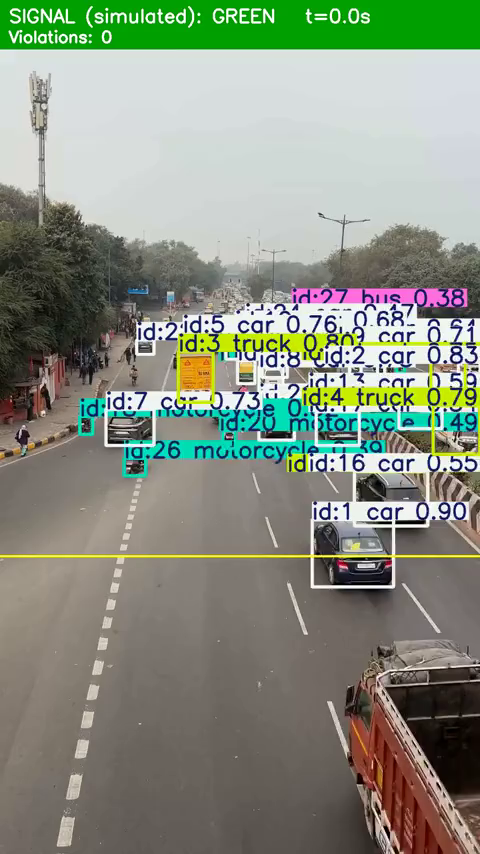

In [3]:
videos = list_videos()
print('Videos in', VIDEO_DIR)
if not videos:
    print('  (none found) - copy your .mp4 files into this folder and re-run from section 2.')
for v in videos:
    print(f'  - {v.name}  ({v.stat().st_size / 1e6:.1f} MB)')

VIDEO_PATH = pick_video(VIDEO_NAME) if READY_VIDEO else None
VIDEO_INFO = video_info(VIDEO_PATH)

if VIDEO_INFO is None:
    print('\nNo usable video selected. Sections that need a video will be skipped.')
else:
    i = VIDEO_INFO
    print(f"\nSelected: {VIDEO_PATH.name}")
    print(f"Original size: {i['width']}x{i['height']}  |  processed at {i['out_w']}x{i['out_h']}")
    print(f"FPS: {i['fps']:.1f}  |  frames: {i['frames']}  |  duration: {i['frames'] / i['fps']:.1f} s")
    first = read_frame(VIDEO_INFO, 0)
    show(first, 500)

## 4. Preview, detector check and calibration grid

Shows one frame with a coordinate grid (labels are fractions of width and height). Use it to choose `STOP_LINE` and, if your video has a traffic light, `SIGNAL_ROI`. The cell also runs the vehicle detector and a traffic-light finder (COCO class 9) on this frame.

- **Yellow line** = the stop line currently set in Settings.
- **Red boxes** = traffic lights found by YOLO (if any). Their fractions are printed so you can paste them into `SIGNAL_ROI`.

Detections on this frame: {'truck': 3, 'car': 1}
No traffic light detected on this frame (normal if the video has none, or it is too small).


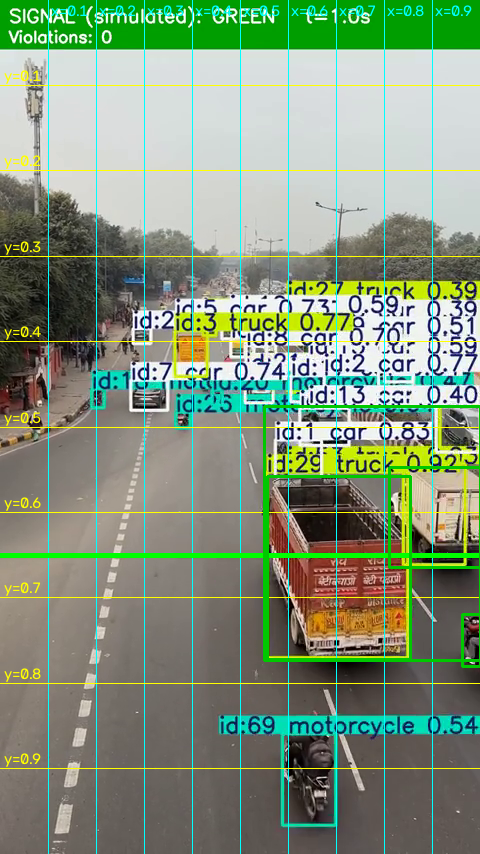

Frame size used for processing: 480x854


In [4]:
def draw_grid(img):
    out = img.copy()
    h, w = out.shape[:2]
    font = cv2.FONT_HERSHEY_SIMPLEX
    for k in range(1, 10):
        f = k / 10
        y, x = int(f * h), int(f * w)
        cv2.line(out, (0, y), (w, y), (0, 255, 255), 1)
        cv2.putText(out, f'y={f:.1f}', (4, max(14, y - 4)), font, 0.5, (0, 255, 255), 1)
        cv2.line(out, (x, 0), (x, h), (255, 255, 0), 1)
        cv2.putText(out, f'x={f:.1f}', (x + 3, 16), font, 0.5, (255, 255, 0), 1)
    return out

if VIDEO_INFO is None:
    print('Skipped: no video.')
else:
    frame = read_frame(VIDEO_INFO, CALIB_FRAME)
    if frame is None:
        frame = read_frame(VIDEO_INFO, 0)
    if frame is None:
        print('Skipped: could not read a frame.')
    else:
        W, H = VIDEO_INFO['out_w'], VIDEO_INFO['out_h']
        view = draw_grid(frame)
        cv2.line(view, rel_to_px(STOP_LINE[0], W, H), rel_to_px(STOP_LINE[1], W, H), (0, 255, 0), 3)
        if SIGNAL_ROI is not None:
            a, b = rel_to_px(SIGNAL_ROI[:2], W, H), rel_to_px(SIGNAL_ROI[2:], W, H)
            cv2.rectangle(view, a, b, (255, 0, 255), 2)

        if READY_DETECT:
            det = load_model(VEHICLE_MODEL)
            if det is not None:
                res = det.predict(frame, conf=0.25, imgsz=IMGSZ, classes=VEHICLE_CLASSES + [9], verbose=False)[0]
                names = det.names
                counts = Counter(names[int(c)] for c in res.boxes.cls.tolist()) if res.boxes is not None else {}
                print('Detections on this frame:', dict(counts))
                lights = []
                if res.boxes is not None:
                    for b, c in zip(res.boxes.xyxy.tolist(), res.boxes.cls.tolist()):
                        if int(c) == 9:
                            lights.append(b)
                        else:
                            cv2.rectangle(view, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (0, 200, 0), 2)
                for n, (x1, y1, x2, y2) in enumerate(lights):
                    cv2.rectangle(view, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 3)
                    print(f'Traffic light {n}: SIGNAL_ROI = ({x1 / W:.3f}, {y1 / H:.3f}, {x2 / W:.3f}, {y2 / H:.3f})')
                if not lights:
                    print('No traffic light detected on this frame (normal if the video has none, or it is too small).')
        else:
            print('Detector not available: showing the grid only.')
        show(view, 900)
        print(f'Frame size used for processing: {W}x{H}')

## 5. Vehicle tracking, stop-line crossing and red-light violations

**Method.** YOLO detects cars, motorcycles, buses and trucks; ByteTrack gives every vehicle a persistent ID. The bottom-centre of each box (where the vehicle touches the road) is compared with the stop line frame by frame. A **crossing** is logged once per ID when the point switches sides of the line. It is a **red-light violation** when the signal has been red for at least `RED_GRACE_S` seconds and the crossing direction matches `TRAFFIC_DIRECTION`.

**Outputs** (in `outputs/`): annotated video, `redlight_violations_log.csv`, and evidence images in `outputs/evidence_redlight/` (full frame + vehicle crop).

`direction` is `down` when the vehicle moves towards the bottom of the frame and `up` towards the top. It is only meaningful for a roughly horizontal stop line.

In [5]:
def run_stop_line_pipeline(info):
    if info is None:
        print('Skipped: no video.')
        return None
    if not READY_DETECT:
        print('Skipped: OpenCV and Ultralytics are both required.')
        return None
    model = load_model(VEHICLE_MODEL)       # fresh model = fresh tracker state
    if model is None:
        return None

    W, H, fps = info['out_w'], info['out_h'], info['fps']
    p1, p2 = rel_to_px(STOP_LINE[0], W, H), rel_to_px(STOP_LINE[1], W, H)

    mode = SIGNAL_MODE
    roi = None
    if mode == 'detect':
        if SIGNAL_ROI is None:
            print("SIGNAL_MODE is 'detect' but SIGNAL_ROI is not set (see section 4). Falling back to 'off'.")
            mode = 'off'
        else:
            roi = (int(SIGNAL_ROI[0] * W), int(SIGNAL_ROI[1] * H), int(SIGNAL_ROI[2] * W), int(SIGNAL_ROI[3] * H))
    if mode not in ('simulate', 'detect', 'off'):
        print(f"Unknown SIGNAL_MODE '{mode}'. Using 'off'.")
        mode = 'off'
    if mode == 'simulate':
        print('NOTE: signal is SIMULATED (not read from the video). Violations are for demonstration only.')

    evid_dir = OUTPUT_DIR / 'evidence_redlight'
    clear_jpgs(evid_dir)
    raw_path = WORK_DIR / 'redlight_annotated_raw.mp4'
    writer = cv2.VideoWriter(str(raw_path), cv2.VideoWriter_fourcc(*'mp4v'), fps / max(1, FRAME_STRIDE), (W, H))
    if not writer.isOpened():
        print('Could not open a video writer. Skipping.')
        return None

    colors = {'red': (0, 0, 255), 'yellow': (0, 200, 255), 'green': (0, 150, 0),
              'unknown': (120, 120, 120), 'off': (80, 80, 80)}
    recent = deque(maxlen=max(1, SIGNAL_SMOOTH_FRAMES))
    state, prev_state, state_since = 'unknown', None, 0.0
    last_side, age = {}, Counter()
    crossed, violators = set(), set()
    crossings_by_state = Counter()
    records = []
    n_frames, start = 0, time.time()

    for idx, frame in iter_frames(info):
        t = idx / fps
        res = model.track(frame, persist=True, tracker='bytetrack.yaml', classes=VEHICLE_CLASSES,
                          conf=VEH_CONF, imgsz=IMGSZ, verbose=False)[0]
        img = res.plot()

        if mode == 'simulate':
            state = scheduled_state(t, SIGNAL_SCHEDULE)
        elif mode == 'detect':
            recent.append(classify_signal(frame, roi))
            voted = Counter(recent).most_common(1)[0][0]
            if voted != 'unknown':
                state = voted
        else:
            state = 'off'
        if state != prev_state:
            prev_state, state_since = state, t
        red_ok = state == 'red' and (t - state_since) >= RED_GRACE_S

        new_violations = []
        boxes = res.boxes
        if boxes is not None and boxes.id is not None:
            for tid, c, (x1, y1, x2, y2) in zip(boxes.id.int().tolist(), boxes.cls.int().tolist(), boxes.xyxy.tolist()):
                age[tid] += 1
                foot = ((x1 + x2) / 2, y2)
                s = side_of_line(foot, p1, p2)
                prev = last_side.get(tid)
                if (prev is not None and prev * s < 0 and tid not in crossed
                        and age[tid] >= MIN_TRACK_AGE and within_segment(foot, p1, p2)):
                    crossed.add(tid)
                    crossings_by_state[state] += 1
                    direction = 'down' if prev < 0 else 'up'
                    if red_ok and TRAFFIC_DIRECTION in ('any', direction):
                        violators.add(tid)
                        new_violations.append((tid, c, direction, (x1, y1, x2, y2)))
                last_side[tid] = s
                if tid in violators:
                    cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 5)
                    cv2.putText(img, 'VIOLATION', (int(x1), max(int(y1) - 8, 80)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)

        cv2.line(img, p1, p2, (0, 255, 255), 3)
        if roi is not None:
            cv2.rectangle(img, (roi[0], roi[1]), (roi[2], roi[3]), colors.get(state, (120, 120, 120)), 2)
        banner = colors.get(state, (120, 120, 120))
        cv2.rectangle(img, (0, 0), (W, 62), banner, -1)
        label = f'SIGNAL{" (SIMULATED)" if mode == "simulate" else ""}: {state.upper()}   violations: {len(violators)}   t={t:.1f}s'
        cv2.putText(img, label, (12, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)

        for tid, c, direction, (x1, y1, x2, y2) in new_violations:
            vid = len(records) + 1
            cname = model.names.get(int(c), str(c)) if isinstance(model.names, dict) else str(c)
            pad = 20
            cx1, cy1 = max(int(x1) - pad, 0), max(int(y1) - pad, 0)
            cx2, cy2 = min(int(x2) + pad, W), min(int(y2) + pad, H)
            full_p = evid_dir / f'redlight_{vid:03d}_{cname}_id{tid}_full.jpg'
            crop_p = evid_dir / f'redlight_{vid:03d}_{cname}_id{tid}_crop.jpg'
            cv2.imwrite(str(full_p), img)
            if cy2 > cy1 and cx2 > cx1:
                cv2.imwrite(str(crop_p), frame[cy1:cy2, cx1:cx2])
            records.append({
                'violation_id': vid, 'type': 'red_light_jump', 'track_id': tid, 'vehicle_class': cname,
                'direction': direction, 'signal_state': state,
                'signal_source': 'simulated' if mode == 'simulate' else ('detected' if mode == 'detect' else 'none'),
                'video_time_s': round(t, 2), 'logged_at': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
                'full_image': full_p.name, 'crop_image': crop_p.name,
            })

        writer.write(img)
        n_frames += 1

    writer.release()
    if n_frames == 0:
        print('No frames were processed.')
        return None

    final, ok = make_playable(raw_path, OUTPUT_DIR / 'redlight_annotated.mp4')
    write_csv(OUTPUT_DIR / 'redlight_violations_log.csv', records)
    print(f'Frames processed: {n_frames} in {time.time() - start:.1f}s')
    print(f'Vehicles that crossed the stop line: {len(crossed)}')
    print('Crossings by signal state:', dict(crossings_by_state))
    print(f'Red-light violations logged: {len(records)}')
    return {'name': 'Red light', 'video_file': VIDEO_PATH.name if VIDEO_PATH else '', 'frames': n_frames,
            'crossings': len(crossed), 'crossings_by_state': dict(crossings_by_state),
            'records': records, 'raw_video': raw_path, 'final_video': final, 'browser_ok': ok,
            'evidence_dir': evid_dir, 'signal_mode': mode}

RL = run_stop_line_pipeline(VIDEO_INFO)
if RL:
    RESULTS['redlight'] = RL
    show_table(RL['records'])
    shown = 0
    for rec in RL['records'][:3]:
        crop = cv2.imread(str(RL['evidence_dir'] / rec['crop_image']))
        if crop is not None:
            print(f"Violation {rec['violation_id']}: {rec['vehicle_class']} at {rec['video_time_s']} s")
            show(crop, 300)

NOTE: signal is SIMULATED (not read from the video). Violations are for demonstration only.
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...


Using Python 3.13.2 environment at: C:\Users\ASUS\AppData\Local\Programs\Python\Python313
Resolved 2 packages in 3.87s
 Downloaded lap
Prepared 1 package in 5.14s
Installed 1 package in 13ms
 + lap==0.5.13



requirements: AutoUpdate success  9.4s


WARNING requirements: Restart runtime or rerun command for updates to take effect



Frames processed: 60 in 20.6s
Vehicles that crossed the stop line: 1
Crossings by signal state: {'green': 1}
Red-light violations logged: 0
(no records)


### Preview of the annotated video

In [6]:
if RESULTS.get('redlight'):
    show_video(RESULTS['redlight']['final_video'], RESULTS['redlight']['browser_ok'])
else:
    print('Skipped: the red-light pipeline did not produce a video.')

Saved: D:\afaf\outputs\redlight_annotated.mp4
Open the saved file with a video player (VLC, Windows Media Player) to watch it.


## 6. Helmet model: weights, optional training, evaluation

The helmet detector must be a YOLO model trained on classes like `full-faced`, `half-faced`, `invalid` and `no helmet`. This cell looks for `best.pt` in these places, newest idea first:

1. `weights/helmet_local/weights/best.pt` (trained by this notebook)
2. `weights/helmet_v2/weights/best.pt` and `weights/helmet/weights/best.pt` (copied from your Colab Drive)
3. `weights/helmet_best.pt`

If none exists, the helmet check is skipped. Either copy your Colab weights into one of those paths, or set `TRAIN_HELMET = True` in Settings (needs `datasets/helmet_dataset.zip`; use a GPU, CPU training takes hours).

In [7]:
HELMET_WEIGHT_CANDIDATES = [
    WEIGHTS_DIR / 'helmet_local' / 'weights' / 'best.pt',
    WEIGHTS_DIR / 'helmet_v2' / 'weights' / 'best.pt',
    WEIGHTS_DIR / 'helmet' / 'weights' / 'best.pt',
    WEIGHTS_DIR / 'helmet_best.pt',
]

def find_helmet_weights():
    for p in HELMET_WEIGHT_CANDIDATES:
        if p.exists() and p.stat().st_size > 0:
            return p
    return None

def prepare_helmet_dataset():
    # Unzip datasets/helmet_dataset.zip once and fix the paths in data.yaml. Returns the yaml path or None.
    zip_path = DATASET_DIR / 'helmet_dataset.zip'
    target = WORK_DIR / 'helmet_dataset'
    yaml_path = target / 'data.yaml'
    if not yaml_path.exists():
        if not zip_path.exists():
            print(f'Dataset archive not found: {zip_path}')
            return None
        try:
            with zipfile.ZipFile(zip_path) as z:
                z.extractall(target)
        except Exception as e:
            print('Could not unzip the dataset:', e)
            return None
    if not yaml_path.exists() or not HAVE_YAML:
        print('data.yaml not found or pyyaml missing.')
        return None
    cfg = yaml.safe_load(open(yaml_path, encoding='utf-8'))
    cfg['path'] = str(target)
    cfg['train'] = 'train/images'
    cfg['val'] = 'valid/images' if (target / 'valid').exists() else 'val/images'
    if (target / 'test' / 'images').exists():
        cfg['test'] = 'test/images'
    with open(yaml_path, 'w', encoding='utf-8') as f:
        yaml.safe_dump(cfg, f)
    return yaml_path

HELMET_YAML = None
if not READY_DETECT:
    print('Skipped: OpenCV and Ultralytics are required.')
else:
    if TRAIN_HELMET:
        HELMET_YAML = prepare_helmet_dataset()
        if HELMET_YAML is None:
            print('Training skipped: dataset not ready.')
        else:
            if not CUDA:
                print('WARNING: no GPU found. Training on CPU is very slow; consider Colab for this step.')
            try:
                YOLO('yolov8s.pt').train(data=str(HELMET_YAML), epochs=HELMET_EPOCHS, imgsz=640, batch=16,
                                         patience=10, project=str(WEIGHTS_DIR), name='helmet_local',
                                         exist_ok=True, device=0 if CUDA else 'cpu')
            except Exception as e:
                print(f'Training stopped: {type(e).__name__}: {e}')

    HELMET_WEIGHTS = find_helmet_weights()
    if HELMET_WEIGHTS is None:
        print('No helmet weights found. Looked for:')
        for p in HELMET_WEIGHT_CANDIDATES:
            print('  ', p)
        print('Copy your trained best.pt to one of these paths, or set TRAIN_HELMET = True. The helmet check will be skipped.')
    else:
        print('Helmet weights:', HELMET_WEIGHTS)
        if EVALUATE_HELMET:
            HELMET_YAML = HELMET_YAML or prepare_helmet_dataset()
            hm = load_model(HELMET_WEIGHTS)
            if hm is not None and HELMET_YAML is not None:
                try:
                    m = hm.val(data=str(HELMET_YAML), imgsz=640, verbose=False)
                    bx = m.box
                    print(f'Overall  P={bx.mp:.3f}  R={bx.mr:.3f}  mAP50={bx.map50:.3f}')
                    print(f'{"class":<12}{"P":>8}{"R":>8}{"mAP50":>8}')
                    for i, ci in enumerate(bx.ap_class_index):
                        print(f'{hm.names[int(ci)]:<12}{bx.p[i]:>8.3f}{bx.r[i]:>8.3f}{bx.ap50[i]:>8.3f}')
                except Exception as e:
                    print(f'Evaluation skipped: {type(e).__name__}: {e}')
            else:
                print('Evaluation skipped: dataset or model not available.')

No helmet weights found. Looked for:
   D:\afaf\weights\helmet_local\weights\best.pt
   D:\afaf\weights\helmet_v2\weights\best.pt
   D:\afaf\weights\helmet\weights\best.pt
   D:\afaf\weights\helmet_best.pt
Copy your trained best.pt to one of these paths, or set TRAIN_HELMET = True. The helmet check will be skipped.


## 7. Helmet violations (riders without helmets)

**Method.**
1. YOLO + ByteTrack track **motorcycles** (COCO class 3) and **persons** (class 0).
2. A person is a *rider* of a motorcycle when most of the person's box lies inside the motorcycle's box.
3. The motorcycle and its riders are cropped together and **enlarged**, then the helmet model runs on the crop.
4. Each motorcycle track **votes** frame by frame (`no helmet` vs `helmet`). A rider is flagged only after `MIN_NOHELMET_VOTES` no-helmet frames that outnumber the helmet frames. One bad frame cannot trigger a violation.

**Outputs:** annotated video, `helmet_violations_log.csv`, evidence images in `outputs/evidence_helmet/`, and a contact sheet of every rider so you can check the model with your own eyes.

**Limits.** The model is only reliable on views similar to its training data (riders seen from the front or side, reasonably large). On top-down or distant footage it may find nothing; the vote summary printed below shows when that happens. Only the rider/passenger with the highest-confidence detection in a crop is judged; a bare-headed passenger behind a helmeted rider can be missed.

In [8]:
def is_invalid_label(name):
    return 'invalid' in name.lower()

def is_no_helmet_label(name):
    n = name.lower().replace('_', ' ').replace('-', ' ')
    return n.startswith('no ') or 'without' in n or n == 'no helmet'

def overlap_ratio(p, m):
    ix1, iy1 = max(p[0], m[0]), max(p[1], m[1])
    ix2, iy2 = min(p[2], m[2]), min(p[3], m[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    return inter / max(1.0, (p[2] - p[0]) * (p[3] - p[1]))

def is_rider(p, m):
    cx = (p[0] + p[2]) / 2
    mw = m[2] - m[0]
    return overlap_ratio(p, m) > 0.2 and (m[0] - 0.3 * mw) <= cx <= (m[2] + 0.3 * mw)

def enlarge(crop):
    h = crop.shape[0]
    if h < TARGET_CROP_H:
        s = TARGET_CROP_H / h
        crop = cv2.resize(crop, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
    return crop

def helmet_vote_from_result(hr, names):
    # Highest-confidence non-'invalid' detection on a crop -> 'no' / 'ok' / None.
    best = None
    if hr.boxes is None:
        return None
    for conf, cls in zip(hr.boxes.conf.tolist(), hr.boxes.cls.tolist()):
        name = names[int(cls)] if isinstance(names, dict) else str(cls)
        if is_invalid_label(name):
            continue
        if best is None or conf > best[1]:
            best = (name, conf)
    if best is None:
        return None
    return 'no' if is_no_helmet_label(best[0]) else 'ok'

def run_helmet_pipeline(info, weights):
    if info is None:
        print('Skipped: no video.')
        return None
    if not READY_DETECT:
        print('Skipped: OpenCV and Ultralytics are both required.')
        return None
    if weights is None:
        print('Skipped: no helmet weights (see section 6).')
        return None
    helmet_model = load_model(weights)
    track_model = load_model(VEHICLE_MODEL)
    if helmet_model is None or track_model is None:
        return None

    W, H, fps = info['out_w'], info['out_h'], info['fps']
    evid_dir = OUTPUT_DIR / 'evidence_helmet'
    clear_jpgs(evid_dir)
    raw_path = WORK_DIR / 'helmet_annotated_raw.mp4'
    writer = cv2.VideoWriter(str(raw_path), cv2.VideoWriter_fourcc(*'mp4v'), fps / max(1, FRAME_STRIDE), (W, H))
    if not writer.isOpened():
        print('Could not open a video writer. Skipping.')
        return None

    votes_no, votes_ok = Counter(), Counter()
    region_of, best_crop = {}, {}
    checked, flagged = set(), set()
    crop_heights, records = [], []
    n_frames, start = 0, time.time()

    for idx, raw in iter_frames(info):
        t = idx / fps
        res = track_model.track(raw, persist=True, tracker='bytetrack.yaml', classes=[0, 3],
                                conf=0.25, imgsz=IMGSZ, verbose=False)[0]
        img = raw.copy()

        motos, persons = {}, []
        boxes = res.boxes
        if boxes is not None and len(boxes):
            ids = boxes.id.int().tolist() if boxes.id is not None else [None] * len(boxes)
            for b, c, tid in zip(boxes.xyxy.tolist(), boxes.cls.int().tolist(), ids):
                if c == 3 and tid is not None:
                    motos[tid] = b
                elif c == 0:
                    persons.append(b)

        crops, meta = [], []
        for tid, m in motos.items():
            riders = [p for p in persons if is_rider(p, m)]
            if not riders:
                continue
            x1 = min([m[0]] + [p[0] for p in riders]); y1 = min([m[1]] + [p[1] for p in riders])
            x2 = max([m[2]] + [p[2] for p in riders]); y2 = max([m[3]] + [p[3] for p in riders])
            padx, pady = 0.1 * (x2 - x1), 0.1 * (y2 - y1)
            x1, y1 = max(int(x1 - padx), 0), max(int(y1 - pady), 0)
            x2, y2 = min(int(x2 + padx), W), min(int(y2 + pady), H)
            crop = raw[y1:y2, x1:x2]
            if crop.shape[0] < MIN_CROP_SIZE or crop.shape[1] < MIN_CROP_SIZE:
                continue
            crop_heights.append(crop.shape[0])
            if tid not in best_crop or crop.size > best_crop[tid].size:
                best_crop[tid] = crop.copy()
            crops.append(enlarge(crop))
            meta.append((tid, (x1, y1, x2, y2)))

        if crops:
            for (tid, region), hr in zip(meta, helmet_model.predict(crops, imgsz=640, conf=HELMET_CONF, verbose=False)):
                checked.add(tid)
                region_of[tid] = region
                v = helmet_vote_from_result(hr, helmet_model.names)
                if v == 'no':
                    votes_no[tid] += 1
                elif v == 'ok':
                    votes_ok[tid] += 1

        new_flags = [tid for tid in checked if tid not in flagged
                     and votes_no[tid] >= MIN_NOHELMET_VOTES and votes_no[tid] > votes_ok[tid]]
        flagged.update(new_flags)

        for tid, m in motos.items():
            if tid in flagged:
                color = (0, 0, 255)
            elif votes_ok[tid] > votes_no[tid]:
                color = (0, 200, 0)
            else:
                color = (180, 180, 180)
            cv2.rectangle(img, (int(m[0]), int(m[1])), (int(m[2]), int(m[3])), color, 4 if tid in flagged else 2)
            label = f'#{tid} no:{votes_no[tid]} ok:{votes_ok[tid]}'
            if tid in flagged:
                label = 'NO HELMET ' + label
            cv2.putText(img, label, (int(m[0]), max(int(m[1]) - 8, 80)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
        cv2.rectangle(img, (0, 0), (W, 62), (40, 40, 40), -1)
        cv2.putText(img, f'Helmet violations: {len(flagged)}   riders checked: {len(checked)}   t={t:.1f}s',
                    (12, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)

        for tid in new_flags:
            vid = len(records) + 1
            x1, y1, x2, y2 = region_of[tid]
            full_p = evid_dir / f'helmet_{vid:03d}_id{tid}_full.jpg'
            crop_p = evid_dir / f'helmet_{vid:03d}_id{tid}_crop.jpg'
            cv2.imwrite(str(full_p), img)
            cv2.imwrite(str(crop_p), raw[y1:y2, x1:x2])
            records.append({
                'violation_id': vid, 'type': 'no_helmet', 'track_id': tid,
                'no_helmet_votes': votes_no[tid], 'helmet_votes': votes_ok[tid],
                'video_time_s': round(t, 2), 'logged_at': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
                'full_image': full_p.name, 'crop_image': crop_p.name,
            })

        writer.write(img)
        n_frames += 1

    writer.release()
    if n_frames == 0:
        print('No frames were processed.')
        return None

    final, ok = make_playable(raw_path, OUTPUT_DIR / 'helmet_annotated.mp4')
    write_csv(OUTPUT_DIR / 'helmet_violations_log.csv', records)

    no_votes = sum(1 for t_ in checked if votes_ok[t_] == 0 and votes_no[t_] == 0)
    print(f'Frames processed: {n_frames} in {time.time() - start:.1f}s')
    print(f'Motorcycles with a detected rider: {len(checked)}')
    if crop_heights:
        print(f'Rider crop height: median {int(np.median(crop_heights))} px, largest {max(crop_heights)} px')
    print(f'Riders with a helmet vote: {sum(1 for t_ in checked if votes_ok[t_] > 0)}'
          f' | with a no-helmet vote: {sum(1 for t_ in checked if votes_no[t_] > 0)}'
          f' | with no votes at all: {no_votes}')
    if checked and no_votes / len(checked) > 0.6:
        print('WARNING: most riders got no votes. The helmet model probably cannot read this camera angle or size, '
              'so "0 violations" does NOT mean everyone wore a helmet. See the contact sheet below.')
    print(f'No-helmet violations flagged: {len(records)}')
    return {'name': 'No helmet', 'video_file': info['path'].name, 'frames': n_frames,
            'riders_checked': len(checked), 'riders_no_votes': no_votes,
            'records': records, 'raw_video': raw_path, 'final_video': final, 'browser_ok': ok,
            'evidence_dir': evid_dir, 'best_crop': best_crop,
            'votes_no': dict(votes_no), 'votes_ok': dict(votes_ok), 'flagged': set(flagged)}

HELMET_PATH = pick_video(HELMET_VIDEO_NAME) if (HELMET_VIDEO_NAME and READY_VIDEO) else VIDEO_PATH
HELMET_INFO = video_info(HELMET_PATH) if HELMET_PATH is not None else None
if HELMET_PATH is not None:
    print('Helmet check video:', HELMET_PATH.name)

HELMET_WEIGHTS = find_helmet_weights() if READY_DETECT else None
HM = run_helmet_pipeline(HELMET_INFO, HELMET_WEIGHTS)
if HM:
    RESULTS['helmet'] = HM
    show_table(HM['records'])

Helmet check video: download.mp4
Skipped: no helmet weights (see section 6).


### Rider contact sheet and helmet video preview

Every tracked rider's best crop, with the votes and verdict (green = helmet, red = flagged, grey = undecided). Use it to judge the model yourself.

In [9]:
HM = RESULTS.get('helmet')
if not HM:
    print('Skipped: the helmet pipeline did not run.')
else:
    crops = HM['best_crop']
    if not crops:
        print('No rider crops were collected (no motorcycle with a rider was found).')
    else:
        TW, TH, COLS, ROWS = 150, 210, 8, 3
        tiles = []
        for tid in sorted(crops):
            tile = cv2.resize(crops[tid], (TW, TH))
            if tid in HM['flagged']:
                color, verdict = (0, 0, 255), 'NO HELMET'
            elif HM['votes_ok'].get(tid, 0) > HM['votes_no'].get(tid, 0):
                color, verdict = (0, 200, 0), 'helmet'
            else:
                color, verdict = (150, 150, 150), 'undecided'
            cv2.rectangle(tile, (0, 0), (TW - 1, TH - 1), color, 3)
            cv2.rectangle(tile, (0, 0), (TW, 34), (0, 0, 0), -1)
            cv2.putText(tile, f'#{tid} {verdict}', (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1)
            cv2.putText(tile, f"no:{HM['votes_no'].get(tid, 0)} ok:{HM['votes_ok'].get(tid, 0)}", (4, 29),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0, 255, 255), 1)
            tiles.append(tile)
        per_page = COLS * ROWS
        blank = np.zeros((TH, TW, 3), np.uint8)
        for s in range(0, min(len(tiles), per_page * 2), per_page):
            page = tiles[s:s + per_page]
            page += [blank] * (per_page - len(page))
            sheet = np.vstack([np.hstack(page[i:i + COLS]) for i in range(0, per_page, COLS)])
            print(f'Riders {s + 1} to {min(s + per_page, len(tiles))} of {len(tiles)}')
            show(sheet, 1200)
        out_sheet = OUTPUT_DIR / 'helmet_rider_sheet.jpg'
        cv2.imwrite(str(out_sheet), sheet)
    show_video(HM['final_video'], HM['browser_ok'])

Skipped: the helmet pipeline did not run.


## 8. Violation highlights video

Cuts a short clip around each logged violation (3 s before, 2 s after) with a title card, one video per pipeline. This is the quickest thing to show in a demo.

In [10]:
def make_highlights(result, out_name, before_s=3.0, after_s=2.0):
    recs = result['records']
    if not recs:
        print(f"{result['name']}: no violations were logged, nothing to cut.")
        return None
    cap = cv2.VideoCapture(str(result['raw_video']))
    if not cap.isOpened():
        print(f"{result['name']}: annotated video could not be opened.")
        return None
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    # the annotated video may contain every n-th frame, so convert seconds using the source FPS ratio
    src_fps = VIDEO_INFO['fps'] if VIDEO_INFO else fps
    ratio = fps / src_fps if src_fps else 1.0
    raw_out = WORK_DIR / f'{out_name}_raw.mp4'
    writer = cv2.VideoWriter(str(raw_out), cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))
    if not writer.isOpened():
        cap.release()
        print('Could not open a video writer.')
        return None
    k = w / 1280
    for rec in recs:
        card = np.zeros((h, w, 3), np.uint8)
        title = f"Violation {rec['violation_id']} of {len(recs)}: {rec['type'].replace('_', ' ').upper()}"
        cv2.putText(card, title, (int(40 * k), h // 2 - 10), cv2.FONT_HERSHEY_SIMPLEX, max(0.6, 1.2 * k), (255, 255, 255), 2)
        cv2.putText(card, f"flagged at {rec['video_time_s']:.1f} s", (int(40 * k), h // 2 + int(40 * k)),
                    cv2.FONT_HERSHEY_SIMPLEX, max(0.5, 0.9 * k), (0, 200, 255), 2)
        for _ in range(max(1, int(fps))):
            writer.write(card)
        a = max(int((rec['video_time_s'] - before_s) * src_fps * ratio), 0)
        b = min(int((rec['video_time_s'] + after_s) * src_fps * ratio), max(total - 1, 0))
        cap.set(cv2.CAP_PROP_POS_FRAMES, a)
        for _ in range(a, b + 1):
            ok, frame = cap.read()
            if not ok:
                break
            writer.write(frame)
    writer.release()
    cap.release()
    final, ok = make_playable(raw_out, OUTPUT_DIR / f'{out_name}.mp4')
    show_video(final, ok)
    return final

made = False
for key, fname in (('redlight', 'redlight_highlights'), ('helmet', 'helmet_highlights')):
    r = RESULTS.get(key)
    if r:
        made = (make_highlights(r, fname) is not None) or made
if not RESULTS:
    print('Skipped: no pipeline produced results.')

Red light: no violations were logged, nothing to cut.


## 9. Evaluation summary

A compact table of what each pipeline found, saved as `outputs/summary.csv`. For your report, also count by hand a few short clips: violations that really happened, violations the system caught, missed ones and false alarms.

**Model metrics** (precision, recall, mAP) for the helmet detector are printed in section 6 when weights and the dataset are available.

In [11]:
rows = []
for key, r in RESULTS.items():
    row = {'check': r['name'], 'video': r['video_file'], 'frames_processed': r['frames'],
           'violations_logged': len(r['records'])}
    if key == 'redlight':
        row['vehicles_crossed_line'] = r['crossings']
        row['signal_source'] = r['signal_mode']
    if key == 'helmet':
        row['riders_checked'] = r['riders_checked']
        row['riders_with_no_votes'] = r['riders_no_votes']
    rows.append(row)

if not rows:
    print('Nothing to summarise yet. Make sure a video is in input_videos/ and the packages are installed (section 2).')
else:
    cols = sorted({k for rw in rows for k in rw}, key=lambda c: (c != 'check', c))
    rows = [{c: rw.get(c, '') for c in cols} for rw in rows]
    write_csv(OUTPUT_DIR / 'summary.csv', rows)
    show_table(rows)
    print('\nFiles in', OUTPUT_DIR)
    for p in sorted(OUTPUT_DIR.glob('*')):
        if p.is_file():
            print('  ', p.name)
    if RESULTS.get('redlight') and RESULTS['redlight']['signal_mode'] == 'simulate':
        print('\nReminder: red-light violations above come from a SIMULATED signal. '
              'Use a video with a visible traffic light and SIGNAL_MODE = "detect" for real results.')

,check,frames_processed,signal_source,vehicles_crossed_line,video,violations_logged
0,Red light,60,simulate,1,download.mp4,0



Files in D:\afaf\outputs
   redlight_annotated.mp4
   summary.csv

Reminder: red-light violations above come from a SIMULATED signal. Use a video with a visible traffic light and SIGNAL_MODE = "detect" for real results.


## 10. Troubleshooting and next steps

| Symptom | What to do |
|---|---|
| `Ultralytics: False` in section 2 | `pip install ultralytics lap` in your environment, restart the kernel. |
| Model download fails | Needs internet once to fetch `yolov8s.pt`. Or put the file in `weights/`. |
| Everything is slow | Set `MAX_FRAMES = 200`, `FRAME_STRIDE = 2`, or `FRAME_MAX_WIDTH = 960`. |
| No crossings counted | Adjust `STOP_LINE` using the grid in section 4. |
| Everything flagged | Set `TRAFFIC_DIRECTION` to `'up'` or `'down'` to match the traffic that must stop. |
| Helmet check skipped | Copy `best.pt` into `weights/helmet_v2/weights/` (see section 6). |
| Helmet: most riders have no votes | The camera angle or rider size does not match the model's training data. Use a closer, front or side view, or retrain on matching images. |
| Signal always `unknown` | Set `SIGNAL_ROI` tightly around the lit lamps; very small or washed-out lights cannot be read by colour. |

**Future work:** number-plate recognition, triple-riding and pillion-helmet checks, a live camera feed, export to ONNX for edge devices, and a larger or merged helmet dataset.